In [1]:
%load_ext cudf.pandas
import os
import json
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import TextVectorization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import warnings
warnings.filterwarnings('ignore')

### **1. Load MS-COCO Dataset**

In [2]:
# Dataset paths (MS-COCO 2014)
directory = "/kaggle/input/datasets/hariwh0/ms-coco-dataset"
if not os.path.exists(directory):
    directory = "/kaggle/input/ms-coco-dataset"

json_path = os.path.join(directory, 'captions', 'annotations', 'captions_train2014.json')
img_dir = os.path.join(directory, 'train2014', 'train2014')

with open(json_path, 'r') as f:
    coco_data = json.load(f)

image_map = {img['id']: img['file_name'] for img in coco_data['images']}

records = []
for ann in coco_data['annotations']:
    filename = image_map[ann['image_id']]
    records.append({
        'image_path': os.path.join(img_dir, filename),
        'caption': ann['caption'],
    })

data = pd.DataFrame(records)
print(f"Total caption pairs loaded: {len(data):,}")
print(f"Unique images: {data['image_path'].nunique():,}")
data.head()

Total caption pairs loaded: 414,113
Unique images: 82,783


,image_path,caption
0,/kaggle/input/datasets/hariwh0/ms-coco-dataset...,A very clean and well decorated empty bathroom
1,/kaggle/input/datasets/hariwh0/ms-coco-dataset...,A panoramic view of a kitchen and all of its a...
2,/kaggle/input/datasets/hariwh0/ms-coco-dataset...,A blue and white bathroom with butterfly theme...
3,/kaggle/input/datasets/hariwh0/ms-coco-dataset...,A panoramic photo of a kitchen and dining room
4,/kaggle/input/datasets/hariwh0/ms-coco-dataset...,A graffiti-ed stop sign across the street from...


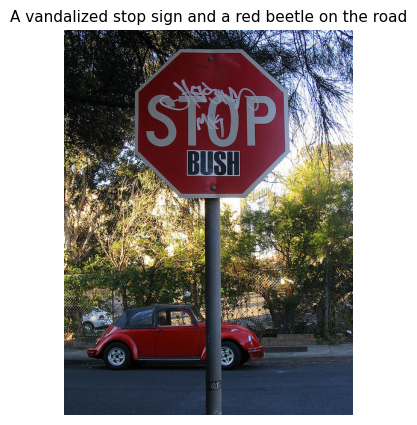

In [3]:
sample = data.iloc[5]
img = Image.open(sample['image_path'])
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(sample['caption'], fontsize=11)
plt.axis('off')
plt.show()

### **2. Text Preprocessing & Sampling**

In [4]:
!pip install cleantext -q
from cleantext import clean

def text_clean(txt):
    txt = clean(txt, lowercase=True, punct=True, extra_spaces=True)
    return f"<start> {txt} <end>"

# Clean all captions in the DataFrame
data['caption'] = data['caption'].map(text_clean)
data.head(3)

,image_path,caption
0,/kaggle/input/datasets/hariwh0/ms-coco-dataset...,<start> a very clean and well decorated empty ...
1,/kaggle/input/datasets/hariwh0/ms-coco-dataset...,<start> a panoramic view of a kitchen and all ...
2,/kaggle/input/datasets/hariwh0/ms-coco-dataset...,<start> a blue and white bathroom with butterf...


In [5]:
print(data.shape)
print(data['image_path'].duplicated().sum())
print(data['caption'].duplicated().sum())

(414113, 2)
331330
15681


In [6]:
# Sampling 15,000 unique images for fast, rich training (~75,000 caption pairs!)
NUM_IMAGES = 15000
unique_images = data['image_path'].drop_duplicates().sample(
    n=min(NUM_IMAGES, data['image_path'].nunique()), random_state=42
).values

# Splitting unique images into Train (80%), Validation (10%), Test (10%)
n_train = int(len(unique_images) * 0.8)
n_val = int(len(unique_images) * 0.1)

train_img_set = set(unique_images[:n_train])
val_img_set = set(unique_images[n_train:n_train + n_val])
test_img_set = set(unique_images[n_train + n_val:])

train_df = data[data['image_path'].isin(train_img_set)].reset_index(drop=True)
val_df = data[data['image_path'].isin(val_img_set)].reset_index(drop=True)
test_df = data[data['image_path'].isin(test_img_set)].reset_index(drop=True)

In [7]:
print(f"Train pairs: {len(train_df):,} (Unique images: {train_df['image_path'].nunique():,})")
print(f"Val pairs:   {len(val_df):,} (Unique images: {val_df['image_path'].nunique():,})")
print(f"Test pairs:  {len(test_df):,} (Unique images: {test_df['image_path'].nunique():,})")

Train pairs: 60,039 (Unique images: 12,000)
Val pairs:   7,505 (Unique images: 1,500)
Test pairs:  7,505 (Unique images: 1,500)


### **Text Vectorization**

In [8]:
max_len = min(max(len(i.split()) for i in train_df['caption']), 20)
print(f"MAX SEQUENCE LENGTH: {max_len}")

MAX SEQUENCE LENGTH: 20


In [9]:
vectorizer = TextVectorization(
    max_tokens=10000,
    output_mode='int',
    output_sequence_length=max_len
)
vectorizer.adapt(train_df['caption'].values)

vocab = vectorizer.get_vocabulary()
VOCAB_SIZE = len(vocab)
SEQ_LEN = max_len - 1

print(f"VOCABULARY SIZE: {VOCAB_SIZE}")
print(f"SAMPLE WORDS: {vocab[:10]}")


# Preparing sequence inputs (x) and shifted targets (y)
train_captions_seq = vectorizer(train_df['caption'].values).numpy()
val_captions_seq = vectorizer(val_df['caption'].values).numpy()

train_captions_x = train_captions_seq[:, :-1]   # input (0 to N-1)
y_train_captions = train_captions_seq[:, 1:]    # target (1 to N)

val_captions_x = val_captions_seq[:, :-1]
y_val_captions = val_captions_seq[:, 1:]

I0000 00:00:1793166343.511078      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13618 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793166343.514221      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


VOCABULARY SIZE: 10000
SAMPLE WORDS: ['', '[UNK]', np.str_('a'), np.str_('end'), np.str_('start'), np.str_('on'), np.str_('of'), np.str_('the'), np.str_('in'), np.str_('with')]


In [10]:
print("Train captions input shape: ", train_captions_x.shape)
print("Train captions target shape:", y_train_captions.shape)

Train captions input shape:  (60039, 19)
Train captions target shape: (60039, 19)


### **3. Openai's vit pre-trained model CLIP Feature Extraction**

In [11]:
import torch as tr
from tqdm import tqdm                           # used to show an instant, animated progress bar for any loop or long-running process
from transformers import CLIPProcessor, CLIPModel

In [12]:
device = tr.device('cuda' if tr.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

processor = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')
clip_model = (CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(device).eval())


unique_paths = list(set(train_df['image_path']).union(set(val_df['image_path'])))
feature_map = {}
batch_size = 64


for i in tqdm(range(0, len(unique_paths), batch_size)):
  batch_paths = unique_paths[i : i + batch_size]
  batch_imgs = [Image.open(p).convert('RGB') for p in batch_paths]

  inputs = processor(images=batch_imgs, return_tensors='pt').to(device)

  with tr.no_grad():
    features = clip_model.get_image_features(**inputs)
    if hasattr(features, 'pooler_output'):
      features = features.pooler_output
    features = features.cpu().numpy()

  for p, f in zip(batch_paths, features):
    feature_map[p] = f


train_imgs = np.array([feature_map[p] for p in train_df['image_path']])
validation_imgs = np.array([feature_map[p] for p in val_df['image_path']])

Using device: cuda


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

100%|██████████| 211/211 [30:35<00:00,  8.70s/it]


In [19]:
print(f"train_imgs shape: {train_imgs.shape}")
print(f"validation_imgs shape: {validation_imgs.shape}")

train_imgs shape: (60039, 512)
validation_imgs shape: (7505, 512)


### **4. Transformer Decoder Architecture & Training**

In [20]:
def masked_loss(y_true, y_pred):
    """Cross-entropy loss that ignores padding 0s so model learns real words."""
    mask = tf.math.not_equal(y_true, 0)
    loss_object = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False, reduction='none')
    loss = loss_object(y_true, y_pred)
    mask = tf.cast(mask, dtype=loss.dtype)
    loss *= mask
    return tf.reduce_sum(loss) / (tf.reduce_sum(mask) + 1e-7)

def masked_accuracy(y_true, y_pred):
    """Accuracy metric ignoring padding 0s."""
    pred_tokens = tf.argmax(y_pred, axis=-1, output_type=y_true.dtype)
    matches = tf.math.equal(y_true, pred_tokens)
    mask = tf.math.not_equal(y_true, 0)
    matches = tf.math.logical_and(matches, mask)
    return tf.reduce_sum(tf.cast(matches, dtype=tf.float32)) / (tf.reduce_sum(tf.cast(mask, dtype=tf.float32)) + 1e-7)

In [21]:
import keras_nlp

# 1. Model Inputs (CLIP 512 image features + caption token sequence)
inputs_image = layers.Input(shape=(512,), name="clip_image_input")
inputs_captions = layers.Input(shape=(SEQ_LEN,), name="caption_input")

# 2. Caption Embedding + Positional Encoding
embedding = layers.Embedding(input_dim=VOCAB_SIZE, output_dim=256)(inputs_captions)
positional_embedding = keras_nlp.layers.PositionEmbedding(sequence_length=SEQ_LEN)(embedding)
caption_embedding = embedding + positional_embedding

# 3. Project CLIP vector from 512 to 256 decoder dimension
img_vector_1 = layers.Dense(256, activation='relu')(inputs_image)
img_vector_2 = layers.Reshape((1, 256))(img_vector_1)

# 4. Deep 2-Layer Transformer Decoder (num_heads=4, intermediate_dim=1024, dropout=0.3)
x = keras_nlp.layers.TransformerDecoder(
    intermediate_dim=1024, num_heads=4, dropout=0.3
)(caption_embedding, encoder_sequence=img_vector_2)

x = keras_nlp.layers.TransformerDecoder(
    intermediate_dim=1024, num_heads=4, dropout=0.3
)(x, encoder_sequence=img_vector_2)

# 5. Output softmax over vocabulary
outputs = layers.Dense(VOCAB_SIZE, activation='softmax')(x)

model = keras.Model(inputs=[inputs_image, inputs_captions], outputs=outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=1.0),
    loss=masked_loss,
    metrics=[masked_accuracy]
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

model.summary()

# 6. Train
history = model.fit(
    x=[train_imgs, train_captions_x],
    y=y_train_captions,
    validation_data=([validation_imgs, val_captions_x], y_val_captions),
    batch_size=64,
    epochs=25,
    callbacks=[early_stopping, reduce_lr]
)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ caption_input       │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 19, 256)   │  2,560,000 │ caption_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clip_image_input    │ (None, 512)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ position_embedding  │ (None, 19, 256)   │      4,864 │ embedding[0][0]   │
│ (PositionEmbedding) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    131,328 │ clip_image_input… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 19, 256)   │          0 │ embedding[0][0],  │
│                     │                   │            │ position_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 256)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_decoder │ (None, 19, 256)   │  1,053,440 │ add[0][0],        │
│ (TransformerDecode… │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_decode… │ (None, 19, 256)   │  1,053,440 │ transformer_deco… │
│ (TransformerDecode… │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 19, 10000) │  2,570,000 │ transformer_deco… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 7,373,072 (28.13 MB)

 Trainable params: 7,373,072 (28.13 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
  3/939 ━━━━━━━━━━━━━━━━━━━━ 36s 39ms/step - loss: 9.2323 - masked_accuracy: 7.7053e-04   

I0000 00:00:1793168803.801527     171 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


939/939 ━━━━━━━━━━━━━━━━━━━━ 64s 44ms/step - loss: 4.7542 - masked_accuracy: 0.2975 - val_loss: 3.7508 - val_masked_accuracy: 0.3588 - learning_rate: 1.0000e-04
Epoch 2/25
939/939 ━━━━━━━━━━━━━━━━━━━━ 26s 28ms/step - loss: 3.5268 - masked_accuracy: 0.3803 - val_loss: 3.3028 - val_masked_accuracy: 0.3999 - learning_rate: 1.0000e-04
Epoch 3/25
939/939 ━━━━━━━━━━━━━━━━━━━━ 26s 28ms/step - loss: 3.1898 - masked_accuracy: 0.4103 - val_loss: 3.0937 - val_masked_accuracy: 0.4209 - learning_rate: 1.0000e-04
Epoch 4/25
939/939 ━━━━━━━━━━━━━━━━━━━━ 26s 27ms/step - loss: 2.9858 - masked_accuracy: 0.4301 - val_loss: 2.9679 - val_masked_accuracy: 0.4333 - learning_rate: 1.0000e-04
Epoch 5/25
939/939 ━━━━━━━━━━━━━━━━━━━━ 26s 28ms/step - loss: 2.8410 - masked_accuracy: 0.4437 - val_loss: 2.8842 - val_masked_accuracy: 0.4425 - learning_rate: 1.0000e-04
Epoch 6/25
939/939 ━━━━━━━━━━━━━━━━━━━━ 26s 28ms/step - loss: 2.7300 - masked_accuracy: 0.4545 - val_loss: 2.8265 - val_masked_accuracy: 0.4497 - learn

### **5. Image Caption Inference & Visual Testing**

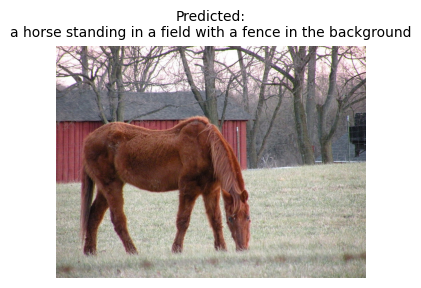

Actual Captions:
 - <start> a brown horse is grazing grass near a red house <end>
 - <start> a skinny horse is grazing in a field <end>
 - <start> a large hours is eating grass in a field <end>
--------------------------------------------------


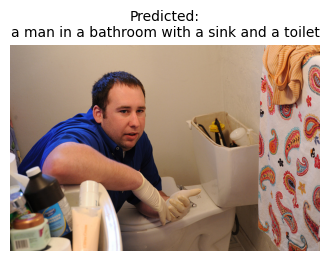

Actual Captions:
 - <start> a man fixing the inside of a toilet <end>
 - <start> a person wearing gloves kneeled down in front of a toilet <end>
 - <start> a man resting his elbow on a toilet stool <end>
--------------------------------------------------


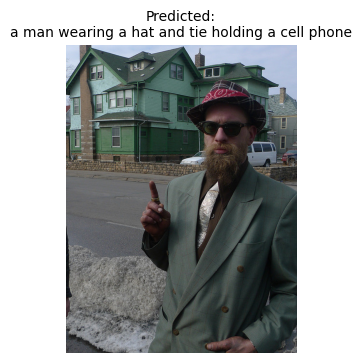

Actual Captions:
 - <start> a man with a beard wearing a suit standing in front of a green house <end>
 - <start> a man in a suit standing at the corner holding a cigar <end>
 - <start> a man standing near the street with a house in the background <end>
--------------------------------------------------


In [30]:
# Inference function with temperature sampling and repetition penalty
index_to_word = {i: word for i, word in enumerate(vocab)}
start_id = int(vectorizer('<start>').numpy()[0])
end_id = int(vectorizer('<end>').numpy()[0])

def extract_single_feature(pil_img):
    """Robust feature extraction supporting all transformers versions."""
    inp = processor(images=pil_img, return_tensors='pt').to(device)
    with tr.no_grad():
        output = clip_model.get_image_features(**inp)
        if hasattr(output, 'pooler_output') and output.pooler_output is not None:
            feat = output.pooler_output
        elif hasattr(output, 'image_embeds') and output.image_embeds is not None:
            feat = output.image_embeds
        elif isinstance(output, tr.Tensor):
            feat = output
        else:
            feat = output[0]
        return feat.detach().cpu().numpy()[0]

def generate_caption(img_vec, max_tokens=SEQ_LEN, temperature=0.0, repetition_penalty=1.2):
    """Generates a natural caption word-by-word."""
    img_input = np.array([img_vec])
    caption_seq = [start_id]
    
    for _ in range(max_tokens):
        padded = caption_seq + [0] * (SEQ_LEN - len(caption_seq))
        caption_input = np.array([padded[:SEQ_LEN]])
        
        preds = model.predict([img_input, caption_input], verbose=0)
        probs_raw = preds[0, len(caption_seq) - 1, :].copy()
        logits = np.log(np.maximum(probs_raw, 1e-10))
        
        # Apply repetition penalty
        for token in set(caption_seq):
            logits[token] /= repetition_penalty
            
        # Temperature scaling and sampling
        if temperature <= 1e-4:
            next_token = int(np.argmax(logits))
        else:
            probs = np.exp(logits / max(temperature, 1e-5))
            probs = probs / np.sum(probs)
            next_token = int(np.random.choice(len(probs), p=probs))
        
        if next_token == end_id or next_token == 0:
            break
        caption_seq.append(next_token)
        
    words = [index_to_word.get(idx, '') for idx in caption_seq if idx not in [start_id, end_id, 0]]
    return ' '.join(words)

# Evaluate on 3 images from Test Set
sample_test_paths = test_df['image_path'].unique()[:3]
for p in sample_test_paths:
    test_img = Image.open(p).convert('RGB')
    feat = extract_single_feature(test_img)
    pred_cap = generate_caption(feat)
    
    plt.figure(figsize=(4, 4))
    plt.imshow(test_img)
    plt.title(f"Predicted:\n{pred_cap}", fontsize=10)
    plt.axis('off')
    plt.show()
    
    actual_caps = test_df[test_df['image_path'] == p]['caption'].values
    print("Actual Captions:")
    for c in actual_caps[:3]:
        print(f" - {c}")
    print("-" * 50)

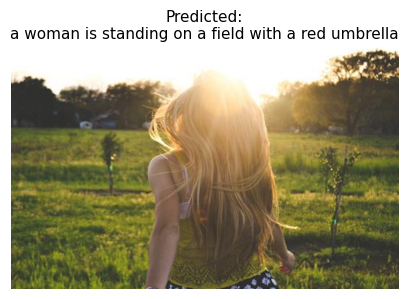

'a woman is standing on a field with a red umbrella'

In [34]:
# Test with external URL (e.g. Unsplash)
import io
import requests

def predict_caption_from_url(image_url, temperature=0.0):
    headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
    response = requests.get(image_url, headers=headers)
    img = Image.open(io.BytesIO(response.content)).convert('RGB')
    
    feat = extract_single_feature(img)
    predicted_caption = generate_caption(feat, temperature=temperature)
    
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Predicted:\n{predicted_caption}", fontsize=11)
    plt.axis('off')
    plt.show()
    
    return predicted_caption

url = "https://lh3.googleusercontent.com/hwau7OVWx96XaME5KpRuJ0I_MscrerK6SbRH1UwYHYaxIDQQtn7RZK02LDSfBzCreidFgDsJeXyqDct6EZiH6vsV=s1280-w1280-h800"
predict_caption_from_url(url)